# Werkzeuge und Daten importieren

## Bibliotheken importieren

In [1]:
# pandas Bibliothek zur Datenverarbeitung importieren
import pandas as pd

# treech Bibliothek für Decision Tree Anwendungen importieren 
from treech import ClassificationTree as ct

# plotly und cufflinks Bibliotheken zur Datenvisalisierung importieren 
from plotly.offline import iplot
import plotly as py
import cufflinks as cf
cf.go_offline()


## Daten importieren

In [3]:
# CSV-Datei importieren
df_jim = pd.read_csv('Jim_bin_125.csv', sep=';')

In [4]:
#Datensatz anzeigen
df_jim

,Geschlecht,Klassenstufe,Schulform,Alter,Apps_Anzahl,Accounts_Anzahl,KontakteHandy_Anzahl,FotosHandy_Anzahl,Freunde_treffen,Sport_machen,...,Ich_verschwende_Zeit_online,NachrichtenApp_nutzen,NavigationsApp_nutzen,ÖPNV_App_nutzen,SchulApp_nutzen,BankApp_nutzen,RadioApp_nutzen,Spielen_Onlinespiele,Schulform_gruppiert,Alter_gruppiert
0,weiblich,11,Gymnasium,15,89,8,328,3000,häufig,häufig,...,selten,häufig,selten,häufig,häufig,selten,selten,selten,Gymnasium,ab 13
1,männlich,6,Gymnasium,15,44,4,7,912,selten,häufig,...,selten,häufig,selten,selten,selten,selten,selten,häufig,Gymnasium,ab 13
2,weiblich,6,Gymnasium,11,20,6,25,0,häufig,selten,...,selten,häufig,selten,selten,selten,selten,selten,häufig,Gymnasium,unter 13
3,weiblich,10,Gymnasium,15,45,3,75,1469,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,selten,Gymnasium,ab 13
4,männlich,7,Sonstiges,12,61,1,30,187,selten,häufig,...,selten,selten,selten,selten,häufig,selten,selten,häufig,nicht Gymnasium,unter 13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1282,weiblich,11,Gymnasium,16,118,18,100,2600,selten,selten,...,selten,selten,selten,selten,häufig,selten,selten,häufig,Gymnasium,ab 13
1283,männlich,12,Gymnasium,17,33,5,185,1343,häufig,häufig,...,selten,häufig,häufig,häufig,häufig,selten,selten,selten,Gymnasium,ab 13
1284,männlich,5,Hauptschule,11,88,2,23,233,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,häufig,nicht Gymnasium,unter 13
1285,weiblich,10,Sonstiges,16,50,6,191,7,selten,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,selten,nicht Gymnasium,ab 13


In [5]:
# Trainingsdaten: 500 zufällige Zeilen
df_training = df_jim.sample(n=500, random_state=12)

# Trainingsdaten entfernen
df_rest = df_jim.drop(df_training.index)

# Validierungsdaten: 500 zufällige Zeilen
df_validation = df_rest.sample(n=500, random_state=43)

# Rest als Testdaten
df_test = df_rest.drop(df_validation.index)

# Entscheidungsbaum trainieren

In [11]:
# Decision Tree initialisieren
tree_jim = ct.DecisionTree(data = df_training, target = "Spielen_Onlinespiele")

In [13]:
# Decision Tree trainieren 
tree_jim.grow_tree(crit='entropy')

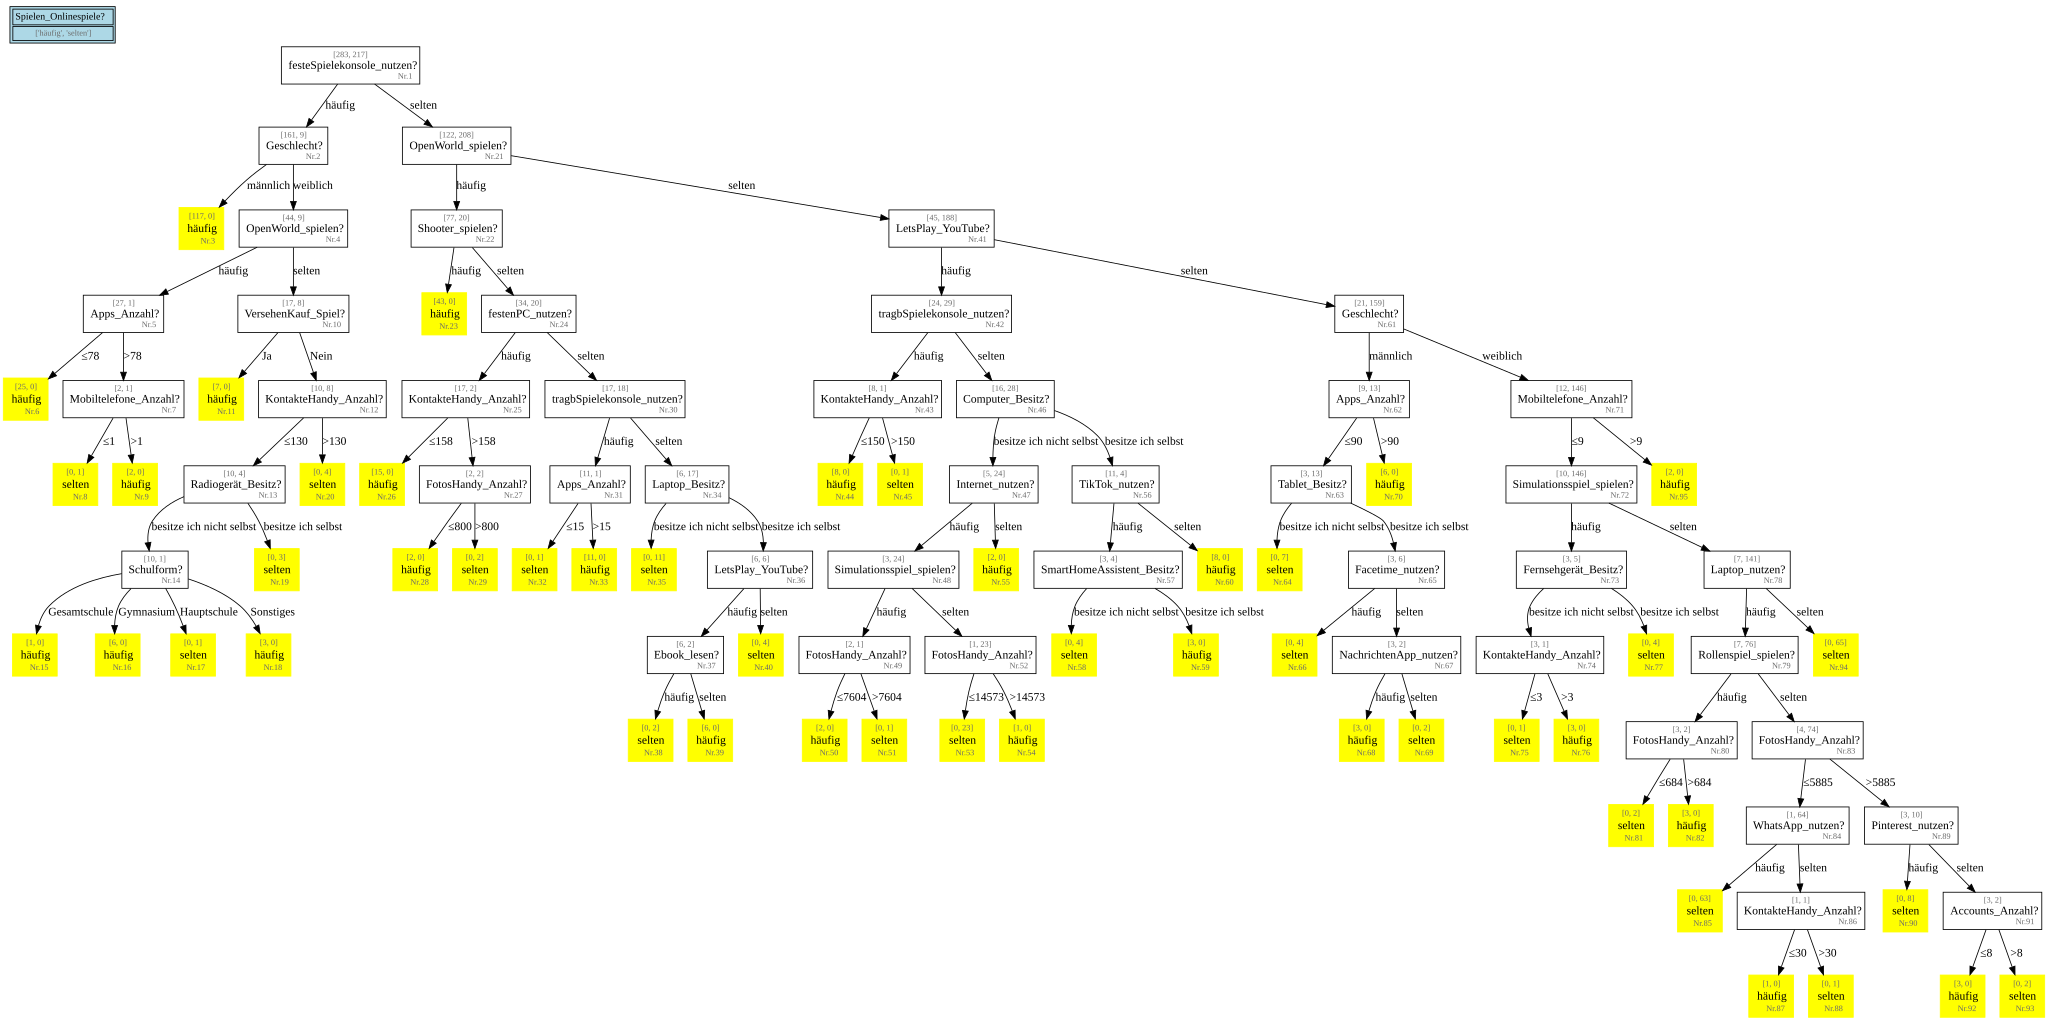

In [14]:
# Decision Tree anzeigen
tree_jim.print_tree()

In [15]:
tree_jim.prediction_accuracy(df_training)

1.0

In [16]:
tree_jim.get_status()#.to_frame()

node_count         95.0
leaf_node_count    49.0
max_depth          12.0
mean_leaf_cases    10.2
dtype: float64

# Entscheidungsbaum mit Testdaten prüfen

In [18]:
df_test

,Geschlecht,Klassenstufe,Schulform,Alter,Apps_Anzahl,Accounts_Anzahl,KontakteHandy_Anzahl,FotosHandy_Anzahl,Freunde_treffen,Sport_machen,...,Ich_verschwende_Zeit_online,NachrichtenApp_nutzen,NavigationsApp_nutzen,ÖPNV_App_nutzen,SchulApp_nutzen,BankApp_nutzen,RadioApp_nutzen,Spielen_Onlinespiele,Schulform_gruppiert,Alter_gruppiert
7,weiblich,12,Gymnasium,17,59,10,193,1753,häufig,selten,...,selten,häufig,selten,selten,häufig,häufig,selten,selten,Gymnasium,ab 13
8,weiblich,5,Gymnasium,11,50,5,56,2,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,selten,Gymnasium,unter 13
11,weiblich,10,Gymnasium,15,88,7,87,4740,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,selten,Gymnasium,ab 13
15,männlich,11,Gymnasium,16,29,5,287,1550,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,häufig,Gymnasium,ab 13
18,männlich,12,Gymnasium,17,80,10,150,1100,häufig,häufig,...,selten,häufig,häufig,selten,häufig,selten,selten,häufig,Gymnasium,ab 13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1270,weiblich,12,Gymnasium,19,50,4,288,2435,häufig,häufig,...,selten,selten,häufig,selten,häufig,häufig,selten,selten,Gymnasium,ab 13
1276,weiblich,5,Gesamtschule,11,57,13,17,222,selten,selten,...,selten,häufig,selten,selten,häufig,selten,selten,selten,nicht Gymnasium,unter 13
1277,weiblich,8,Realschule,13,52,3,67,3,selten,häufig,...,selten,selten,selten,selten,häufig,selten,selten,selten,nicht Gymnasium,ab 13
1284,männlich,5,Hauptschule,11,88,2,23,233,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,häufig,nicht Gymnasium,unter 13


In [19]:
df_validation

,Geschlecht,Klassenstufe,Schulform,Alter,Apps_Anzahl,Accounts_Anzahl,KontakteHandy_Anzahl,FotosHandy_Anzahl,Freunde_treffen,Sport_machen,...,Ich_verschwende_Zeit_online,NachrichtenApp_nutzen,NavigationsApp_nutzen,ÖPNV_App_nutzen,SchulApp_nutzen,BankApp_nutzen,RadioApp_nutzen,Spielen_Onlinespiele,Schulform_gruppiert,Alter_gruppiert
498,männlich,5,Gymnasium,11,36,6,45,578,häufig,häufig,...,selten,häufig,häufig,selten,häufig,häufig,selten,häufig,Gymnasium,unter 13
492,weiblich,10,Gymnasium,16,6,2,45,5775,häufig,häufig,...,selten,häufig,häufig,selten,häufig,selten,selten,selten,Gymnasium,ab 13
1004,weiblich,5,Gymnasium,12,73,70,83,438,häufig,selten,...,selten,häufig,selten,selten,häufig,selten,selten,selten,Gymnasium,unter 13
1210,männlich,8,Gymnasium,13,14,5,117,64,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,häufig,Gymnasium,ab 13
934,weiblich,5,Gymnasium,10,171,3,482,259,selten,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,selten,Gymnasium,unter 13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
936,männlich,7,Sonstiges,14,22,3,74,743,häufig,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,häufig,nicht Gymnasium,ab 13
693,männlich,6,Gymnasium,11,25,1,12,0,selten,häufig,...,selten,häufig,selten,selten,häufig,selten,selten,häufig,Gymnasium,unter 13
245,männlich,8,Sonstiges,14,72,2,56,3672,häufig,selten,...,selten,häufig,selten,selten,häufig,selten,selten,häufig,nicht Gymnasium,ab 13
1119,männlich,5,Gymnasium,11,0,0,0,0,häufig,häufig,...,selten,selten,selten,selten,selten,selten,selten,häufig,Gymnasium,unter 13


In [20]:
tree_jim.prediction_accuracy(df_validation)

0.83

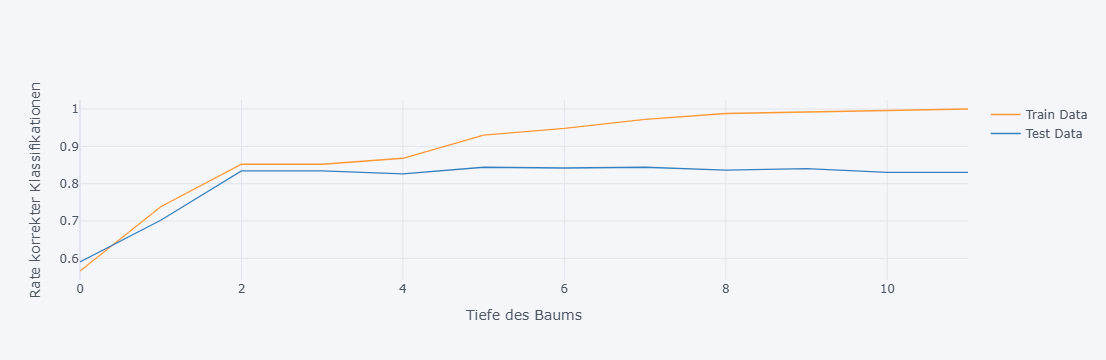

In [21]:
tree_jim.evaluation_depth(df_training, df_validation).iplot(xTitle='Tiefe des Baums', yTitle='Rate korrekter Klassifikationen')

In [22]:
tree_jim.prediction_accuracy(df_test)

0.8257839721254355

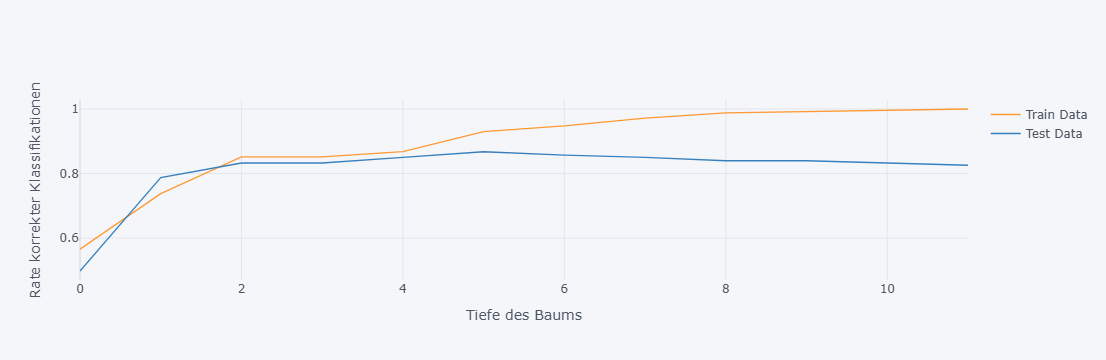

In [23]:
tree_jim.evaluation_depth(df_training, df_test).iplot(xTitle='Tiefe des Baums', yTitle='Rate korrekter Klassifikationen')

# Entscheidungsbaum optimieren

In [25]:
tree_jim.validation_pruning(df_validation)

Test Node: 7
Prune Node: 7
Node-Count 93
New Test-Score 0.83
Test Node: 5
Prune Node: 5
Node-Count 91
New Test-Score 0.83
Test Node: 14
Prune Node: 14
Node-Count 87
New Test-Score 0.83
Test Node: 13
Prune Node: 13
Node-Count 85
New Test-Score 0.832
Test Node: 12
Prune Node: 12
Node-Count 83
New Test-Score 0.836
Test Node: 10
Prune Node: 10
Node-Count 81
New Test-Score 0.836
Test Node: 4
Prune Node: 4
Node-Count 79
New Test-Score 0.836
Test Node: 2
Prune Node: 2
Node-Count 77
New Test-Score 0.836
Test Node: 27
Prune Node: 27
Node-Count 75
New Test-Score 0.838
Test Node: 25
Prune Node: 25
Node-Count 73
New Test-Score 0.838
Test Node: 31
Prune Node: 31
Node-Count 71
New Test-Score 0.842
Test Node: 37
Prune Node: 37
Node-Count 69
New Test-Score 0.846
Test Node: 36
Test Node: 34
Test Node: 30
Test Node: 24
Test Node: 22
Test Node: 43
Prune Node: 43
Node-Count 67
New Test-Score 0.85
Test Node: 49
Prune Node: 49
Node-Count 65
New Test-Score 0.85
Test Node: 52
Prune Node: 52
Node-Count 63
New 

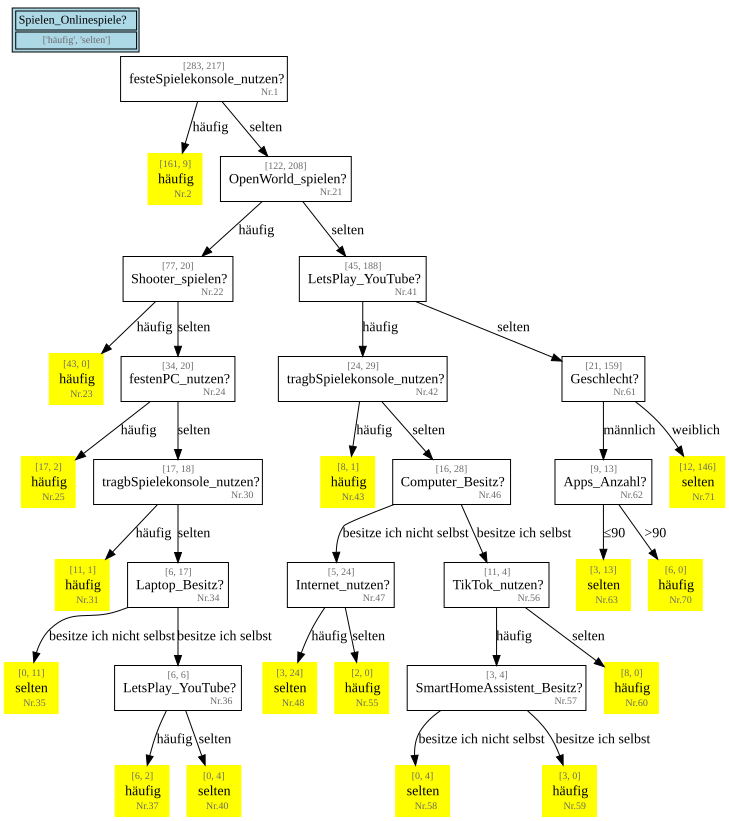

In [26]:
tree_jim.print_tree()

In [27]:
tree_jim.get_status()

node_count         31.00
leaf_node_count    16.00
max_depth           8.00
mean_leaf_cases    31.25
dtype: float64

In [28]:
tree_jim.prediction_accuracy(df_training)

0.934

In [30]:
tree_jim.prediction_accuracy(df_validation)

0.874

In [31]:
tree_jim.prediction_accuracy(df_test)

0.8710801393728222

In [38]:
tree_jim.evaluation_depth(df_training, df_test).iplot(xTitle='Tiefe des Baums', yTitle='Rate korrekter Klassifikationen')